QUESTION 1

part A

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
np.random.seed(532)

E = lambda -> 10
var = lambda -> 10

E = 1 / lambda -> 2
var = 1 / lambda^2 -> 4

E = 1 / p -> 5
var = 19.9999 = 20

part B

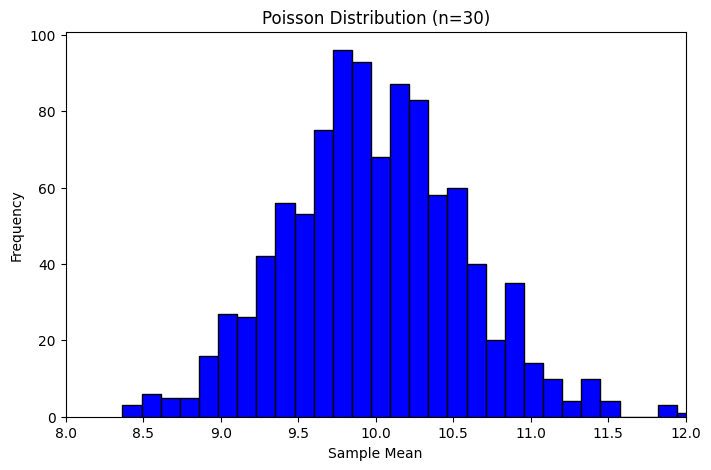

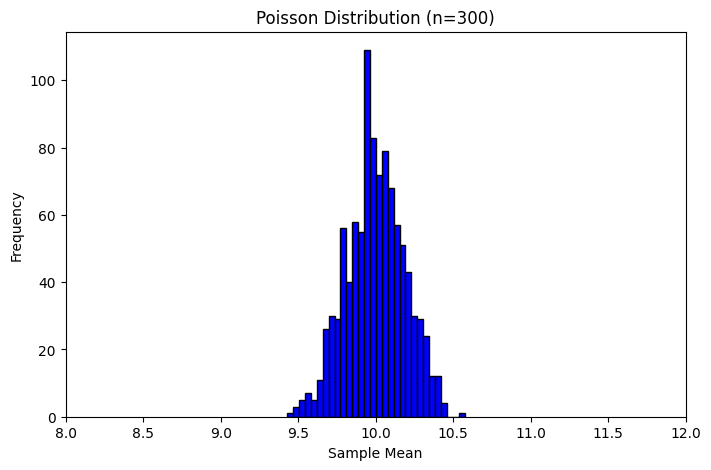

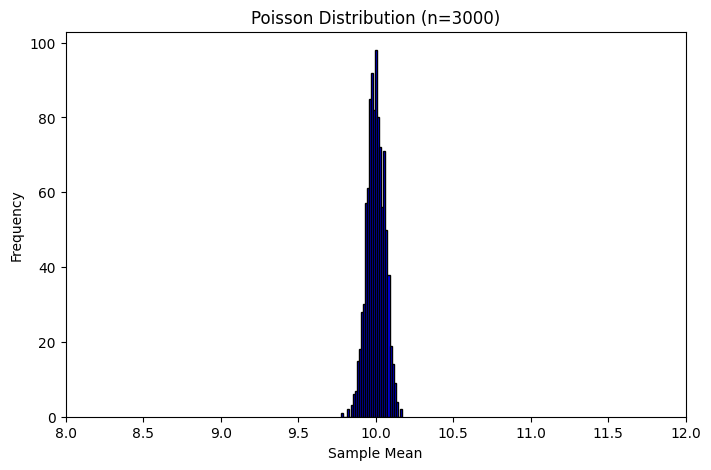

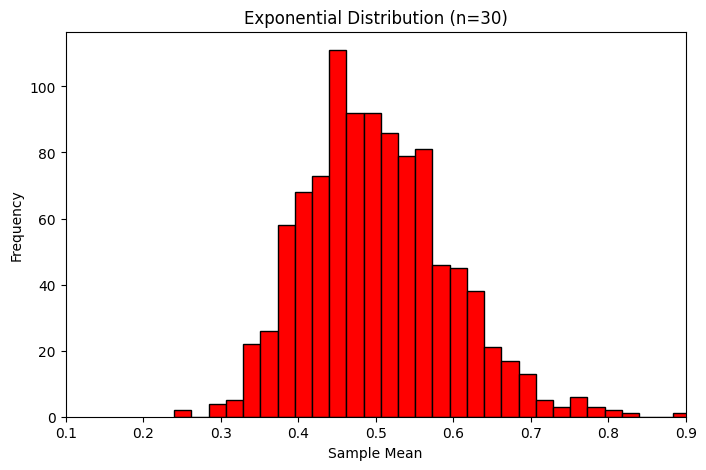

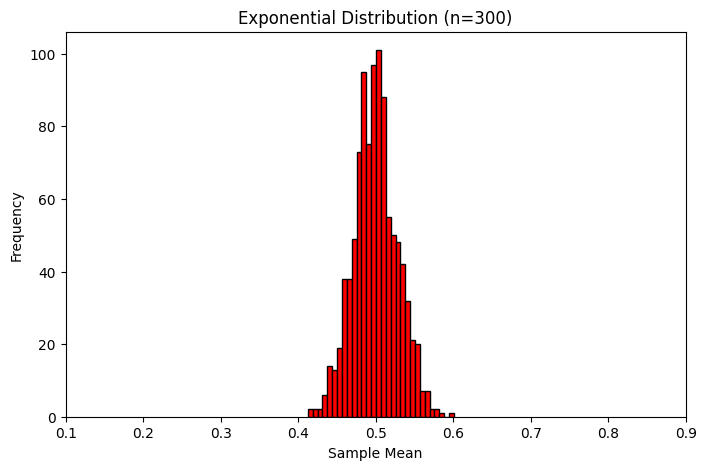

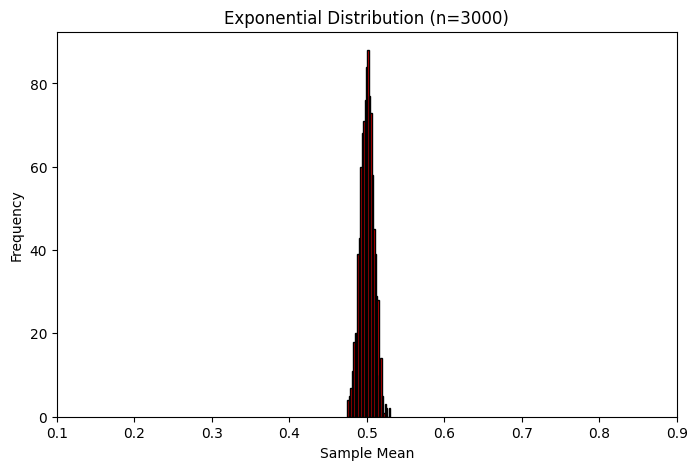

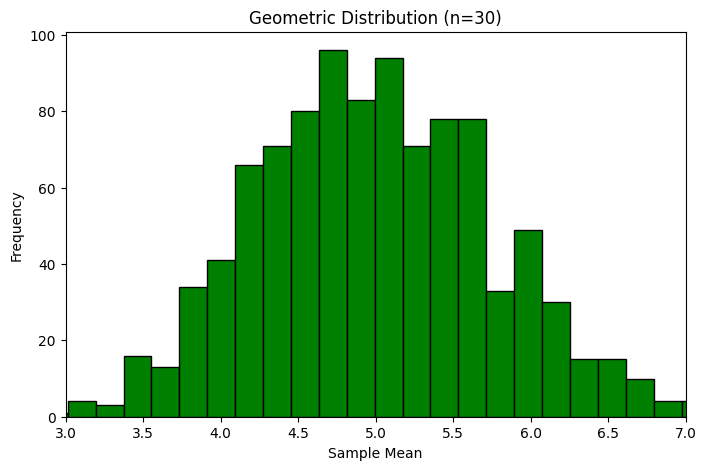

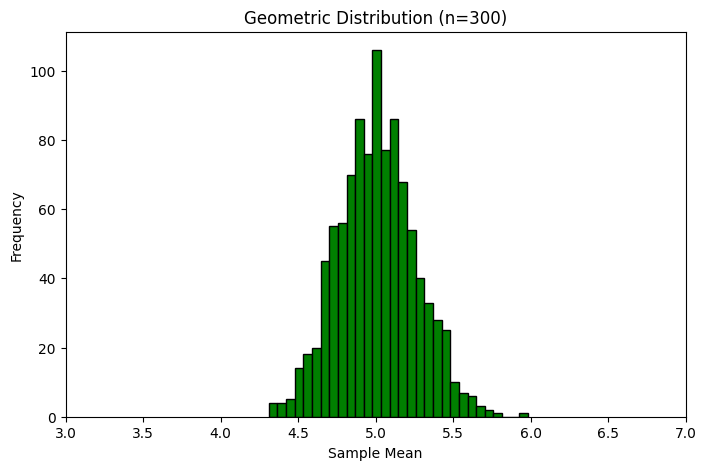

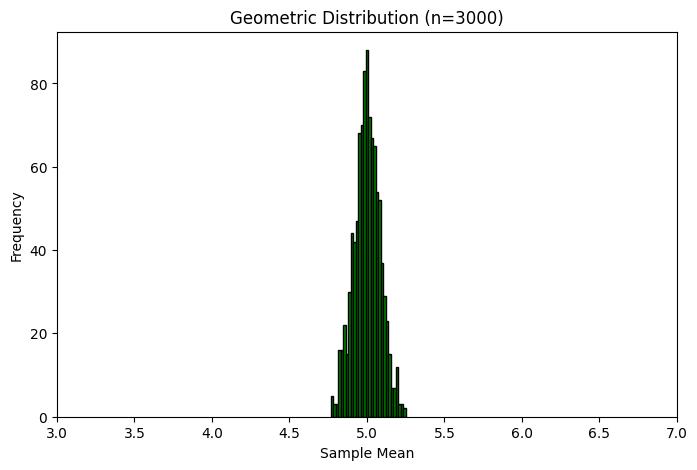

In [83]:

samples = [30, 300, 3000]
################
lis1 = []
lis2 = []
lis3 = []
for sample in samples:
    poi = np.random.poisson(10, (1000, sample))
    exp = np.random.exponential(0.5, (1000, sample))
    geo = np.random.geometric(0.2, (1000, sample))
    sample_mean1 = np.mean(poi, 1)
    sample_mean2 = np.mean(exp, 1)
    sample_mean3 = np.mean(geo, 1)
    lis1.append(sample_mean1)
    lis2.append(sample_mean2)
    lis3.append(sample_mean3)
###############
def plt1(data_list, title_prefix):
    for i, sample in enumerate(samples):
        sample_means = data_list[i]
        plt.figure(figsize=(8, 5))
        plt.hist(sample_means, bins=30, color='blue', edgecolor='black')
        plt.title(f"{title_prefix} Distribution (n={sample})")
        plt.xlabel("Sample Mean")
        plt.xlim(8, 12)
        plt.ylabel("Frequency")
        plt.show()
def plt2(data_list, title_prefix):
    for i, sample in enumerate(samples):
        sample_means = data_list[i]
        plt.figure(figsize=(8, 5))
        plt.hist(sample_means, bins=30, color='red', edgecolor='black')
        plt.title(f"{title_prefix} Distribution (n={sample})")
        plt.xlabel("Sample Mean")
        plt.xlim(0.1, 0.9)
        plt.ylabel("Frequency")
        plt.show()
def plt3(data_list, title_prefix):
    for i, sample in enumerate(samples):
        sample_means = data_list[i]
        plt.figure(figsize=(8, 5))
        plt.hist(sample_means, bins=30, color='green', edgecolor='black')
        plt.title(f"{title_prefix} Distribution (n={sample})")
        plt.xlabel("Sample Mean")
        plt.xlim(3, 7)
        plt.ylabel("Frequency")
        plt.show()
###################
plt1(lis1, "Poisson")
plt2(lis2, "Exponential")
plt3(lis3, "Geometric")

part c

In [84]:
def f(data_list):
    for i, sample in enumerate(samples):
        means = data_list[i]
        sample_mean = np.mean(means)
        sample_std_error = np.std(means) / np.sqrt(sample)
        print(f"n={sample}: Mean = {sample_mean:.4f}, Standard Error = {sample_std_error:.4f}")
f(lis1)
f(lis2)
f(lis3)


n=30: Mean = 9.9895, Standard Error = 0.1048
n=300: Mean = 9.9971, Standard Error = 0.0108
n=3000: Mean = 10.0000, Standard Error = 0.0010
n=30: Mean = 0.5015, Standard Error = 0.0168
n=300: Mean = 0.4995, Standard Error = 0.0016
n=3000: Mean = 0.5000, Standard Error = 0.0002
n=30: Mean = 5.0117, Standard Error = 0.1447
n=300: Mean = 5.0069, Standard Error = 0.0145
n=3000: Mean = 4.9994, Standard Error = 0.0015


By increasing the number of samples, we get closer to the true mean and our error rate also decreases.

pard d

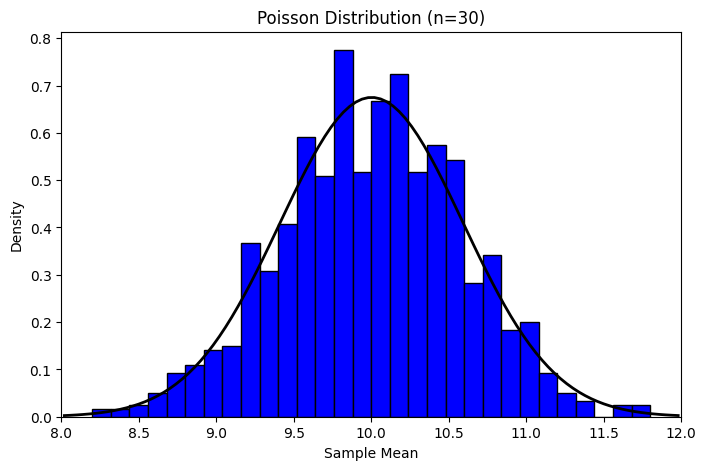

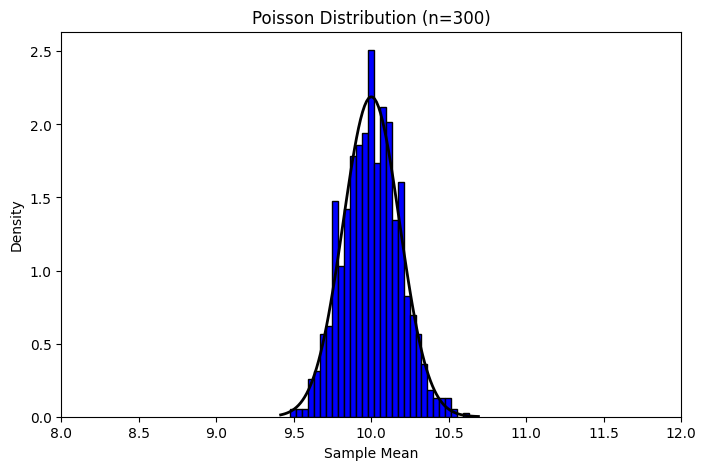

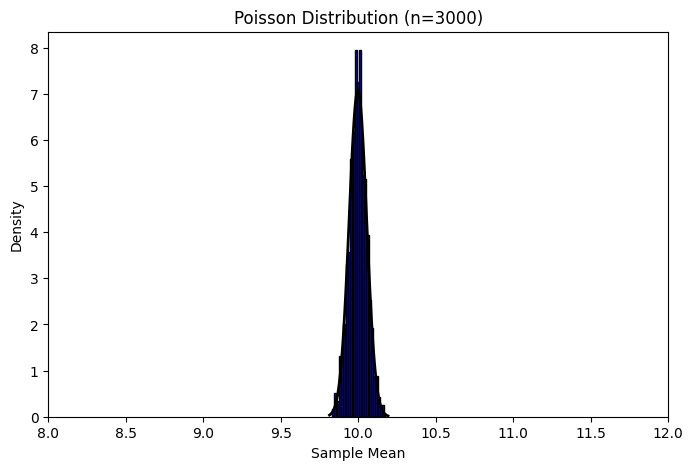

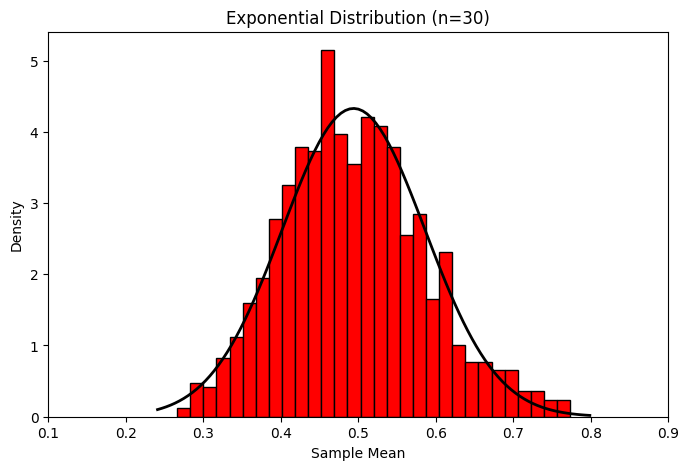

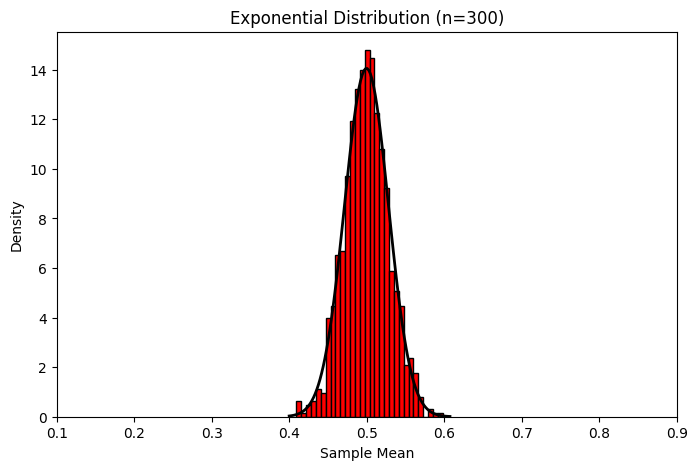

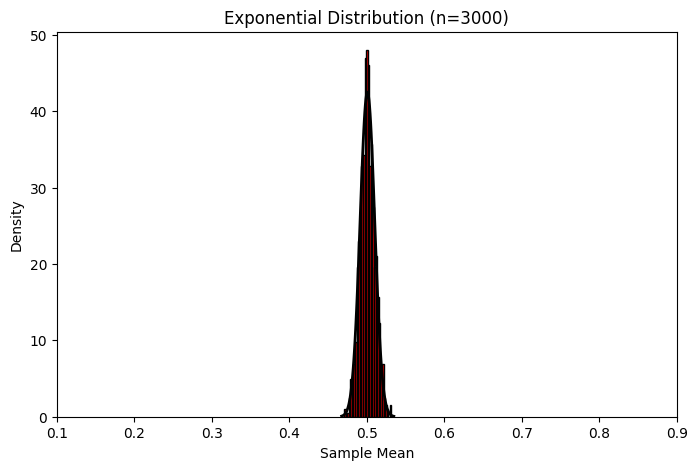

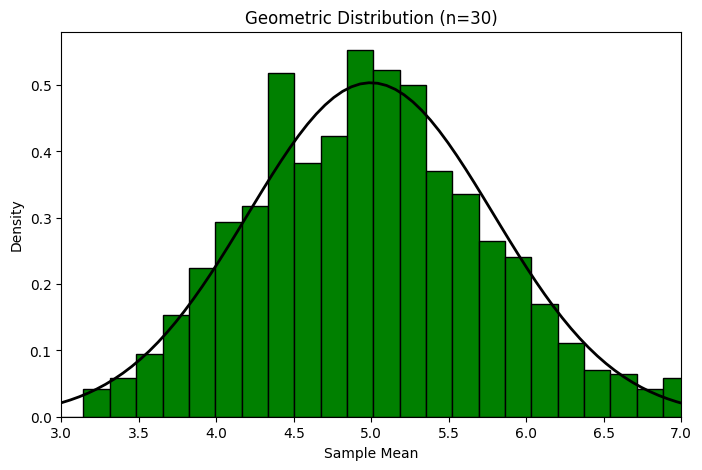

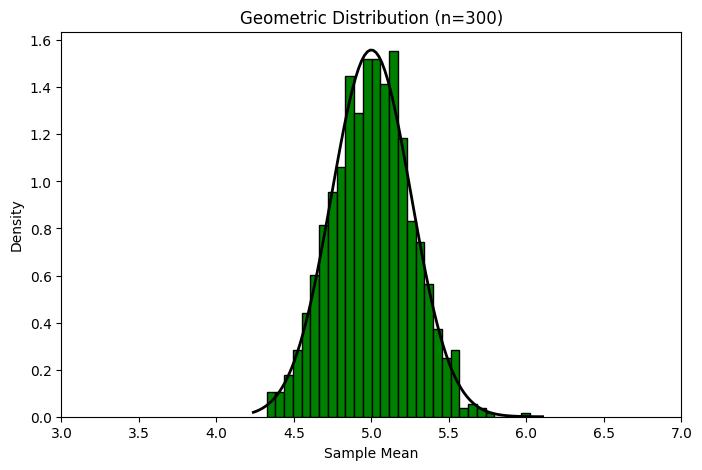

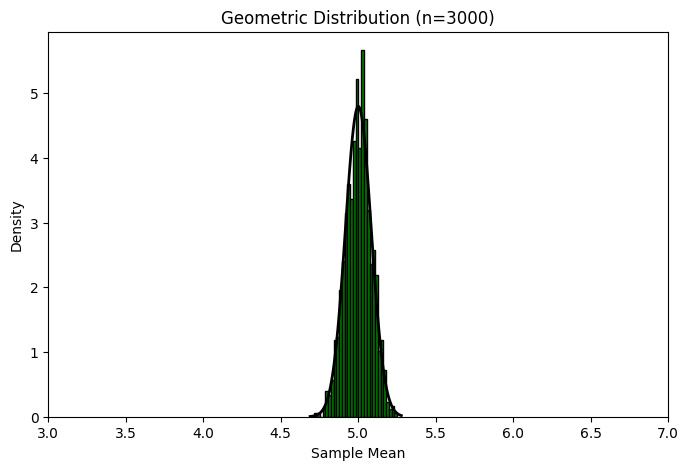

In [85]:
samples = [30, 300, 3000]
################
lis1 = []
lis2 = []
lis3 = []
for sample in samples:
    poi = np.random.poisson(10, (1000, sample))
    exp = np.random.exponential(0.5, (1000, sample))
    geo = np.random.geometric(0.2, (1000, sample))
    sample_mean1 = np.mean(poi, 1)
    sample_mean2 = np.mean(exp, 1)
    sample_mean3 = np.mean(geo, 1)
    lis1.append(sample_mean1)
    lis2.append(sample_mean2)
    lis3.append(sample_mean3)
###############
def pltt_with_normal(data_list, title_prefix, color, xlim_values, bins=30):
    for i, sample in enumerate(samples):
        sample_means = data_list[i]
        mean = np.mean(sample_means)
        std_dev = np.std(sample_means)
        plt.figure(figsize=(8, 5))
        plt.hist(sample_means, bins=bins, color=color, edgecolor='black', density=True, label="Sample Means")
        xmin, xmax = plt.xlim()
        x = np.linspace(xmin, xmax, 100)
        p = norm.pdf(x, mean, std_dev)
        plt.plot(x, p, 'black', lw=2, label=f'Normal Distribution\n(mu={mean:.2f}, sigma={std_dev:.2f})')
        plt.title(f"{title_prefix} Distribution (n={samples[i]})")
        plt.xlabel("Sample Mean")
        plt.ylabel("Density")
        plt.xlim(xlim_values)
        plt.show()
pltt_with_normal(lis1, "Poisson", 'blue', (8, 12))
pltt_with_normal(lis2, "Exponential", 'red', (0.1, 0.9))
pltt_with_normal(lis3, "Geometric", 'green', (3, 7))


As the sample size increases, the distributions obtained from each distribution become closer to the normal distribution.
The parameters of the resulting normal distribution depend on the mean and standard deviation of the original distributions, which change with the sample size.

part e


n=30: Mean = 4.9343, Standard Error = 0.7176
n=300: Mean = 5.1237, Standard Error = 0.2252
n=3000: Mean = 5.2599, Standard Error = 0.0704


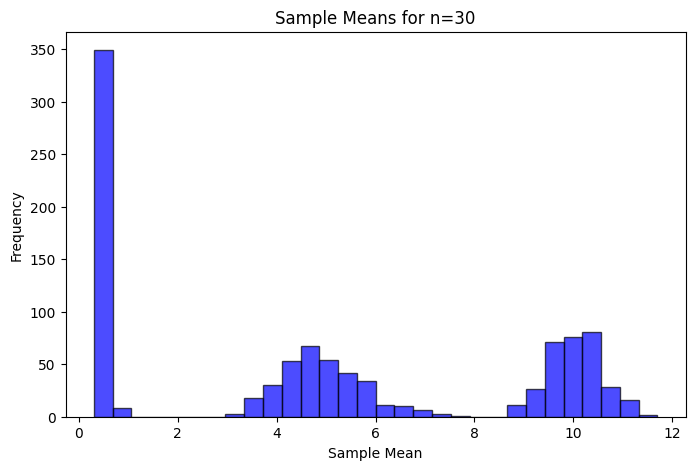

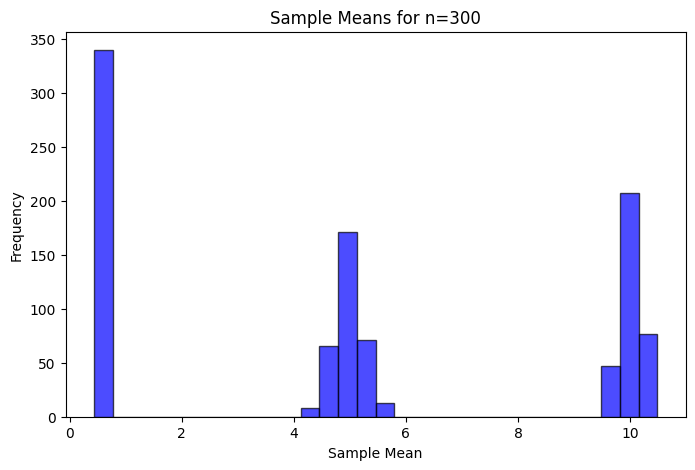

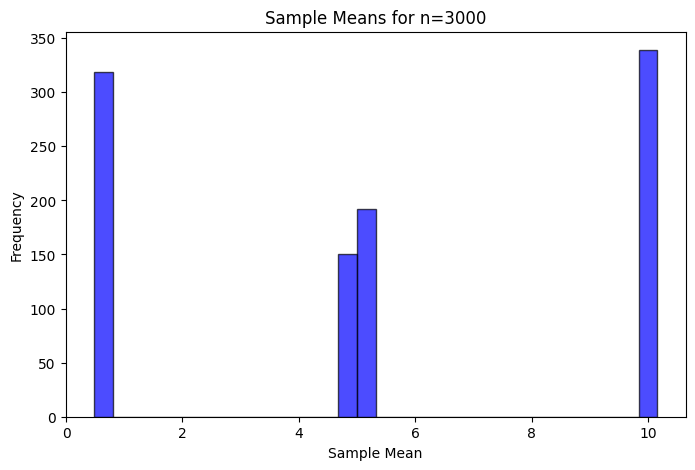

In [86]:
samples = [30, 300, 3000]
################
lis1 = []
for sample in samples:
    sample_mean1 = []
    for _ in range(1000):
        temp = np.random.choice(['poisson', 'exponential', 'geometric'], p=[1/3, 1/3, 1/3])
        if temp == 'poisson':
            io = np.random.poisson(10, sample)
            sample_mean1.append(np.mean(io))
        elif temp == 'exponential':
            io = np.random.exponential(0.5, sample)
            sample_mean1.append(np.mean(io))
        elif temp == 'geometric':
            io = np.random.geometric(0.2, sample)
            sample_mean1.append(np.mean(io))
    lis1.append(np.array(sample_mean1))
###############
def rep(data_list, sample_sizes):
    for i, sample in enumerate(sample_sizes):
        means = data_list[i]
        sample_mean = np.mean(means)
        sample_std_error = np.std(means) / np.sqrt(sample_sizes[i])
        print(f"n={sample}: Mean = {sample_mean:.4f}, Standard Error = {sample_std_error:.4f}")
rep(lis1, samples)

###############
def pltt(data_list, sample_sizes):
    for i, sample in enumerate(sample_sizes):
        plt.figure(figsize=(8, 5))
        plt.hist(data_list[i], bins=30, color='blue', edgecolor='black', alpha=0.7)
        plt.title(f"Sample Means for n={sample}")
        plt.xlabel("Sample Mean")
        plt.ylabel("Frequency")
        plt.show()
pltt(lis1, samples)


part f

No, because our variables are not i.i.d, so we can't specify a formula for that. For the variables to be i.i.d, they would have to be independent of each other, which is not the case.